# Búsqueda local e *Iterated Local Search* (ILS)

**Serie:** Metaheurísticas desde cero · Notebook 03 · Anterior: [02 · Métodos constructivos](02-metodos-constructivos.ipynb) · Siguiente: [04 · VNS y LNS](04-vns-lns.ipynb)

## Tabla de contenido
1. El marco de la búsqueda local
2. Utilidades
3. Vecindarios: swap, 2-opt, or-opt y 3-opt (con deltas $O(1)$ verificados)
4. Estrategias: primera mejora vs. mejor mejora
5. Comparación de vecindarios
6. Evaluación incremental: cuánto cuesta no recalcular
7. Listas de vecinos y *don't-look bits*
8. Óptimos locales y estructura del paisaje (el "gran valle")
9. Perturbación e *Iterated Local Search*
10. Criterios de aceptación
11. Fuerza de la perturbación
12. ILS vs. reinicios aleatorios a igual tiempo
13. Ventajas y limitaciones · Resumen · Ejercicios · Referencias

## Qué vas a aprender / Prerrequisitos

**Vas a aprender a**
- diseñar una búsqueda local: representación, vecindario, estrategia de exploración y criterio de parada;
- implementar los vecindarios swap, 2-opt, or-opt y 3-opt con **evaluación incremental en $O(1)$**, y *verificar* que el delta coincide con la recomputación completa;
- acelerar 2-opt con **listas de vecinos** y ***don't-look bits***;
- explicar por qué los óptimos locales de un TSP no están dispersos al azar (estructura de "gran valle") y cómo se aprovecha;
- construir una **ILS** (perturbación + búsqueda local + criterio de aceptación) y medir el efecto de la **fuerza de perturbación** y de la **aceptación**.

**Prerrequisitos:** [01 · Introducción](../00-fundamentos/01-introduccion-optimizacion-combinatoria.ipynb) y [02 · Constructivos](02-metodos-constructivos.ipynb) (TSP, gap, cota de Held–Karp, vecino más cercano).

In [1]:
import itertools, math, time
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(7)

## 1. El marco de la búsqueda local

Una **búsqueda local** parte de una solución $s$ y la mejora repetidamente reemplazándola por un vecino mejor, hasta que no queda ninguno: se detiene en un **óptimo local** respecto del vecindario $N$.

$$
s_{t+1}\in\{s'\in N(s_t):\ f(s')<f(s_t)\},\qquad \text{parar cuando } \{s'\in N(s_t): f(s')<f(s_t)\}=\varnothing .
$$

```
s ← solución_inicial
repetir:
    elegir s' ∈ N(s) con f(s') < f(s)     # según la estrategia (primera / mejor mejora)
    si no existe: parar                    # s es óptimo local respecto de N
    s ← s'
devolver s
```

**Decisiones de diseño**

| Decisión | Opciones | Efecto |
|---|---|---|
| Representación | permutación, vector de aristas, array con posiciones | costo de aplicar un movimiento |
| Vecindario $N$ | swap, 2-opt, or-opt, 3-opt, ... | calidad del óptimo local vs. costo por iteración |
| Estrategia | **primera mejora** (acepta el primer vecino que mejora) vs. **mejor mejora** (examina todos y toma el mejor) | costo por paso vs. dirección del descenso |
| Evaluación | recomputar $f$ ($O(n)$) vs. **delta incremental** ($O(1)$) | factor $n$ en la velocidad |
| Solución inicial | aleatoria, constructiva | calidad final y tiempo de convergencia |

La búsqueda local es **pura intensificación**: converge rápido, pero se queda atrapada. Las metaheurísticas de esta serie son, en esencia, maneras de **escapar** de los óptimos locales; la más simple es perturbar y volver a descender, la **ILS** (sección 9).

## 2. Utilidades

In [2]:
def crear_tsp(n, rng):
    pts = rng.random((n, 2)); return pts, cdist(pts, pts)

def longitud_tour(D, tour):
    tour = np.asarray(tour); return D[tour, np.roll(tour, -1)].sum()

def es_permutacion(sol, n):
    sol = np.asarray(sol); return sol.shape == (n,) and np.array_equal(np.sort(sol), np.arange(n))

def graficar_tour(pts, tour, ax=None, titulo=""):
    ax = ax or plt.gca(); t = np.append(tour, tour[0])
    ax.plot(pts[t, 0], pts[t, 1], "-o", ms=3, lw=1.1); ax.set_title(titulo, fontsize=10)
    ax.set_aspect("equal"); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])

def gap(c, ref): return 100.0 * (c - ref) / ref

def vecino_mas_cercano(D, inicio=0):
    n = len(D); vis = np.zeros(n, bool); t = [inicio]; vis[inicio] = True
    for _ in range(n - 1):
        j = int(np.where(vis, np.inf, D[t[-1]]).argmin()); t.append(j); vis[j] = True
    return np.array(t)

def aristas(t):
    # Conjunto de aristas del ciclo como enteros min*n+max (independiente de rotación y sentido)
    t = np.asarray(t); n = len(t); u, v = t, np.roll(t, -1)
    return set((np.minimum(u, v) * n + np.maximum(u, v)).tolist())

def dist_aristas(t1, t2):
    # Número de aristas de t1 que no están en t2 (distancia de "bonding" entre tours)
    return len(t1) - len(aristas(t1) & aristas(t2))

# --- Cota inferior de Held-Karp (versión compacta de la notebook 02) para reportar gaps honestos ---
def prim_mst(W):
    n = len(W); en = np.zeros(n, bool); en[0] = True; dist = W[0].copy(); padre = np.zeros(n, int); ar = []; tot = 0.0
    for _ in range(n - 1):
        j = int(np.where(en, np.inf, dist).argmin()); ar.append((int(padre[j]), j)); tot += dist[j]; en[j] = True
        m = (W[j] < dist) & ~en; dist[m] = W[j][m]; padre[m] = j
    return ar, tot

def cota_hk(D, UB, iters=150, alpha=2.0):
    n = len(D); pi = np.zeros(n); mejor = -np.inf
    for _ in range(iters):
        W = D + pi[:, None] + pi[None, :]
        ar, peso = prim_mst(W[1:, 1:]); grado = np.zeros(n)
        for a, b in ar: grado[a + 1] += 1; grado[b + 1] += 1
        dos = np.argsort(W[0, 1:])[:2] + 1; peso += W[0, dos].sum(); grado[0] = 2; grado[dos] += 1
        L = peso - 2 * pi.sum(); mejor = max(mejor, L); g = grado - 2
        if not g.any(): break
        pi = pi + alpha * (UB - L) / (g @ g) * g; alpha *= 0.97
    return mejor

pts50, D50 = crear_tsp(50, np.random.default_rng(11))
print("n =", len(D50), "| longitud de un tour aleatorio:", round(longitud_tour(D50, rng.permutation(50)), 3))

n = 50 | longitud de un tour aleatorio: 28.363


## 3. Vecindarios para permutaciones

Un movimiento transforma el tour $t$ (arreglo de $n$ ciudades, ciclo cerrado) en un vecino. Todos los vecindarios siguientes se evalúan con un **delta**: la diferencia de longitud solo depende de las aristas que cambian, no de las $n$ aristas del tour.

### 3.1 Los cuatro vecindarios

| Vecindario | Movimiento | Aristas que cambian | Tamaño $\|N\|$ |
|---|---|---|---|
| **Swap** | intercambiar las ciudades de las posiciones $i<j$ (no adyacentes) | 4 | $\frac{n(n-3)}{2}$ |
| **2-opt** | invertir el tramo $t[i{+}1..j]$ | 2 | $\frac{n(n-3)}{2}$ |
| **Or-opt** | mover un tramo de $L\in\{1,2,3\}$ ciudades a otra posición (opcionalmente invertido) | 3 | $\approx n\,(n-L-1)$ por $L$ (×2 si se permite invertir, $L>1$) |
| **3-opt (inserción de tramo)** | intercambiar dos tramos adyacentes: $\dots t_i\,[A]\,[B]\,t_{k+1}\dots\to \dots t_i\,[B]\,[A]\,t_{k+1}\dots$ | 3 | $\binom{n}{3}$ |

El 3-opt completo incluye además reconexiones con inversiones; aquí usamos la variante "pura" sin inversión (la *segment insertion*), que contiene al or-opt como caso particular (tramo corto).

Los deltas (con $a=t_i$, $b=t_{i+1}$, $c=t_j$, $d=t_{j+1}$, índices cíclicos):

$$
\Delta_{\text{2-opt}}=d_{ac}+d_{bd}-d_{ab}-d_{cd}
$$

$$
\Delta_{\text{swap}}= d_{a\,e}+d_{e\,c}+d_{d\,b}+d_{b\,f}-d_{ab}-d_{bc}-d_{de}-d_{ef}\quad\text{con } a,b,c \text{ vecinos de } t_i \text{ y } d,e,f \text{ vecinos de } t_j.
$$

Para or-opt, con el tramo $[s_0..s_L]$ entre $p'$ (antes) y $n'$ (después), insertado entre $p$ y $q$:

$$
\Delta_{\text{or-opt}}=\underbrace{d_{p s_0}+d_{s_L q}-d_{pq}}_{\text{inserción}}-\underbrace{\left(d_{p' s_0}+d_{s_L n'}-d_{p'n'}\right)}_{\text{extracción}}.
$$

Implementamos primero cada delta y cada movimiento de forma **escalar** (claro y verificable) y luego versiones vectorizadas para explorar el vecindario completo.

In [3]:
# ---------- 2-opt: invertir t[i+1..j], 0 <= i, i+2 <= j <= n-1, excluyendo (i=0, j=n-1) ----------
def delta_2opt(D, t, i, j):
    n = len(t); a, b, c, d = t[i], t[i + 1], t[j], t[(j + 1) % n]
    return D[a, c] + D[b, d] - D[a, b] - D[c, d]

def aplicar_2opt(t, mov):
    i, j = mov; u = t.copy(); u[i + 1:j + 1] = u[i + 1:j + 1][::-1]; return u

# ---------- swap: intercambiar posiciones i<j no adyacentes ----------
def delta_swap(D, t, i, j):
    n = len(t); a, b, c = t[i - 1], t[i], t[(i + 1) % n]; d, e, f = t[j - 1], t[j], t[(j + 1) % n]
    return D[a, e] + D[e, c] + D[d, b] + D[b, f] - D[a, b] - D[b, c] - D[d, e] - D[e, f]

def aplicar_swap(t, mov):
    i, j = mov; u = t.copy(); u[i], u[j] = u[j], u[i]; return u

# ---------- or-opt: mover el tramo t[i..i+L-1] (cíclico) entre rest[m] y rest[m+1], opcionalmente invertido ----------
def _or_partes(t, i, L):
    ti = np.roll(t, -i); return ti[:L], ti[L:], ti[-1], ti[L]       # tramo, resto (de 'sig' a 'ant'), ant, sig

def delta_oropt(D, t, i, L, m, inv):
    seg, rest, ant, sig = _or_partes(t, i, L); s0, sL = seg[0], seg[-1]; p, q = rest[m], rest[m + 1]
    ext = D[ant, s0] + D[sL, sig] - D[ant, sig]
    ins = (D[p, sL] + D[s0, q] if inv else D[p, s0] + D[sL, q]) - D[p, q]
    return ins - ext

def aplicar_oropt(t, mov):
    i, L, m, inv = mov; seg, rest, _, _ = _or_partes(t, i, L)
    return np.concatenate([rest[:m + 1], seg[::-1] if inv else seg, rest[m + 1:]])

# ---------- 3-opt (inserción de tramo): t[:i+1] + t[j+1..k] + t[i+1..j] + t[k+1:], 0 <= i < j < k <= n-1 ----------
def delta_3opt(D, t, i, j, k):
    n = len(t); ti, ti1, tj, tj1, tk, tk1 = t[i], t[i + 1], t[j], t[j + 1], t[k], t[(k + 1) % n]
    return D[ti, tj1] + D[tk, ti1] + D[tj, tk1] - D[ti, ti1] - D[tj, tj1] - D[tk, tk1]

def aplicar_3opt(t, mov):
    i, j, k = mov; return np.concatenate([t[:i + 1], t[j + 1:k + 1], t[i + 1:j + 1], t[k + 1:]])

APLICAR = {"2opt": aplicar_2opt, "swap": aplicar_swap, "oropt": aplicar_oropt, "3opt": aplicar_3opt}

### 3.2 Verificación: delta incremental = recomputación completa
Para cada vecindario sorteamos miles de movimientos válidos sobre tours aleatorios, aplicamos el movimiento y comprobamos que (i) el resultado sigue siendo una **permutación** y (ii) $\Delta$ coincide con $f(\text{nuevo})-f(\text{viejo})$ con tolerancia numérica. Si alguna fórmula estuviera mal, el `assert` fallaría.

In [4]:
def mov_aleatorio(nombre, n, r):
    # Sortea argumentos válidos para cada vecindario.
    if nombre in ("2opt", "swap"):
        while True:
            i = int(r.integers(0, n - 2)); j = int(r.integers(i + 2, n))
            if not (i == 0 and j == n - 1): return (i, j)
    if nombre == "oropt":
        L = int(r.integers(1, 4)); i = int(r.integers(0, n)); m = int(r.integers(0, n - L - 1)); inv = bool(r.integers(0, 2)); return (i, L, m, inv)
    i = int(r.integers(0, n - 2)); j = int(r.integers(i + 1, n - 1)); k = int(r.integers(j + 1, n)); return (i, j, k)

DELTA = {"2opt": delta_2opt, "swap": delta_swap, "oropt": delta_oropt, "3opt": delta_3opt}
r = np.random.default_rng(1); n_t = 30; max_err = {}
for nombre in DELTA:
    err = 0.0
    for _ in range(3000):
        Dm = crear_tsp(n_t, r)[1]; t = r.permutation(n_t); mov = mov_aleatorio(nombre, n_t, r)
        d_inc = DELTA[nombre](Dm, t, *mov); u = APLICAR[nombre](t, mov)
        assert es_permutacion(u, n_t)
        err = max(err, abs(d_inc - (longitud_tour(Dm, u) - longitud_tour(Dm, t))))
    max_err[nombre] = err
print("Máximo error |delta - recomputación| en 3000 movimientos por vecindario:")
for k, v in max_err.items(): print(f"  {k:>6}: {v:.2e}")
assert all(v < 1e-9 for v in max_err.values())

Máximo error |delta - recomputación| en 3000 movimientos por vecindario:
    2opt: 1.17e-14
    swap: 9.05e-15
   oropt: 1.22e-14
    3opt: 8.44e-15


### 3.3 Verificación del tamaño de los vecindarios
Enumeramos en $n=12$ todos los movimientos de cada tipo, contamos los movimientos **generados** y los **tours distintos** que producen (excluyendo la identidad), y comparamos con las fórmulas.

In [5]:
def generar_movs(nombre, n):
    if nombre in ("2opt", "swap"):
        return [(i, j) for i in range(n - 2) for j in range(i + 2, n) if not (i == 0 and j == n - 1)]
    if nombre == "oropt":
        return [(i, L, m, inv) for L in (1, 2, 3) for i in range(n) for m in range(n - L - 1) for inv in ((False,) if L == 1 else (False, True))]
    return [(i, j, k) for i in range(n) for j in range(i + 1, n) for k in range(j + 1, n)]

n_e = 12; base = np.arange(n_e); e0 = frozenset(aristas(base))
formulas = {"2opt": n_e * (n_e - 3) // 2, "swap": n_e * (n_e - 3) // 2,
            "oropt": sum(n_e * (n_e - L - 1) * (1 if L == 1 else 2) for L in (1, 2, 3)), "3opt": math.comb(n_e, 3)}
print(f"{'vecindario':>10} {'generados':>10} {'fórmula':>9} {'tours distintos':>16}")
for nombre in APLICAR:
    movs = generar_movs(nombre, n_e)
    distintos = {frozenset(aristas(APLICAR[nombre](base, m))) for m in movs} - {e0}
    print(f"{nombre:>10} {len(movs):>10} {formulas[nombre]:>9} {len(distintos):>16}")
    assert len(movs) == formulas[nombre]

vecindario  generados   fórmula  tours distintos
      2opt         54        54               54
      swap         54        54               54
     oropt        528       528              396
      3opt        220       220              220


Los "tours distintos" pueden ser menos que los movimientos generados porque algunos movimientos distintos producen el mismo ciclo (p. ej. mover una ciudad una posición adelante equivale a mover su vecina una atrás). Para 2-opt, swap y 3-opt coincide con el número de movimientos generados; para or-opt hay duplicados.

### 3.4 Exploración vectorizada del vecindario completo
Para barrer todo el vecindario (mejor mejora) calculamos los deltas de una fila entera con NumPy y nos quedamos con el menor. Cada `scan_*` devuelve `(mejor_delta, movimiento, nº de evaluaciones)`; `movimiento=None` significa "óptimo local respecto de este vecindario".

In [6]:
TOL = 1e-12

def scan_2opt(D, t):
    n = len(t); tn = np.roll(t, -1); mejor = (0.0, None); ev = 0
    for i in range(n - 2):
        js = np.arange(i + 2, n if i > 0 else n - 1)
        if js.size == 0: continue
        a, b = t[i], t[i + 1]; c, d = t[js], tn[js]
        dl = D[a, c] + D[b, d] - D[a, b] - D[c, d]; ev += js.size; k = int(dl.argmin())
        if dl[k] < mejor[0] - TOL: mejor = (dl[k], (i, int(js[k])))
    return mejor[0], mejor[1], ev

def scan_swap(D, t):
    n = len(t); tp = np.roll(t, 1); tn = np.roll(t, -1); mejor = (0.0, None); ev = 0
    for i in range(n - 2):
        js = np.arange(i + 2, n if i > 0 else n - 1)
        if js.size == 0: continue
        a, b, c = tp[i], t[i], tn[i]; d, e, f = tp[js], t[js], tn[js]
        dl = D[a, e] + D[e, c] + D[d, b] + D[b, f] - D[a, b] - D[b, c] - D[d, e] - D[e, f]; ev += js.size; k = int(dl.argmin())
        if dl[k] < mejor[0] - TOL: mejor = (dl[k], (i, int(js[k])))
    return mejor[0], mejor[1], ev

def scan_oropt(D, t):
    n = len(t); mejor = (0.0, None); ev = 0
    for L in (1, 2, 3):
        for i in range(n):
            seg, rest, ant, sig = _or_partes(t, i, L); s0, sL = seg[0], seg[-1]
            p, q = rest[:-1], rest[1:]; ext = D[ant, s0] + D[sL, sig] - D[ant, sig]; base = D[p, q]
            for inv in ((False,) if L == 1 else (False, True)):
                dl = (D[p, sL] + D[s0, q] if inv else D[p, s0] + D[sL, q]) - base - ext; ev += dl.size; m = int(dl.argmin())
                if dl[m] < mejor[0] - TOL: mejor = (dl[m], (i, L, m, inv))
    return mejor[0], mejor[1], ev

def scan_3opt(D, t):
    n = len(t); mejor = (0.0, None); ev = 0
    for i in range(n - 2):
        J = np.arange(i + 1, n - 1)[:, None]; K = np.arange(i + 2, n)[None, :]
        ok = K > J
        ti, ti1 = t[i], t[i + 1]; tj, tj1 = t[J], t[J + 1]; tk, tk1 = t[K], t[(K + 1) % n]
        dl = D[ti, tj1] + D[tk, ti1] + D[tj, tk1] - D[ti, ti1] - D[tj, tj1] - D[tk, tk1]
        dl = np.where(ok, dl, np.inf); ev += int(ok.sum()); f = int(dl.argmin()); a, b = divmod(f, dl.shape[1])
        if dl[a, b] < mejor[0] - TOL: mejor = (dl[a, b], (i, int(J[a, 0]), int(K[0, b])))
    return mejor[0], mejor[1], ev

SCAN = {"2opt": scan_2opt, "swap": scan_swap, "oropt": scan_oropt, "3opt": scan_3opt}

# Verificación: el mejor delta del barrido coincide con la recomputación y con la fórmula escalar
r = np.random.default_rng(5); n_t = 25
for nombre, scan in SCAN.items():
    for _ in range(100):
        Dm = crear_tsp(n_t, r)[1]; t = r.permutation(n_t)
        dl, mov, ev = scan(Dm, t); u = APLICAR[nombre](t, mov)
        assert es_permutacion(u, n_t) and abs(dl - (longitud_tour(Dm, u) - longitud_tour(Dm, t))) < 1e-9
        assert abs(dl - DELTA[nombre](Dm, t, *mov)) < 1e-9
    print(f"{nombre:>6}: 100 barridos verificados | evaluaciones por barrido (n={n_t}): {ev}")

  2opt: 100 barridos verificados | evaluaciones por barrido (n=25): 275
  swap: 100 barridos verificados | evaluaciones por barrido (n=25): 275
 oropt: 100 barridos verificados | evaluaciones por barrido (n=25): 2725


  3opt: 100 barridos verificados | evaluaciones por barrido (n=25): 2300


## 4. Estrategias: primera mejora vs. mejor mejora

- **Mejor mejora** (*best improvement*, descenso por máxima pendiente): examina el vecindario completo y aplica el mejor movimiento. Cada paso es caro pero "bien dirigido".
- **Primera mejora** (*first improvement*): aplica el primer movimiento que mejora. Pasos baratos, pero más pasos y una trayectoria distinta (sensible al orden de exploración).

Implementamos 2-opt **escalar** (doble bucle con deltas $O(1)$ sobre listas de Python) con ambas estrategias y contamos evaluaciones y movimientos. Partimos de las mismas 30 soluciones aleatorias en $n=50$.

estrategia  costo medio  costo mejor  movs medios  evals medias  s/corrida
     mejor        6.440        6.080         44.3         53188      0.006
   primera        6.414        6.142        142.9         48286      0.005


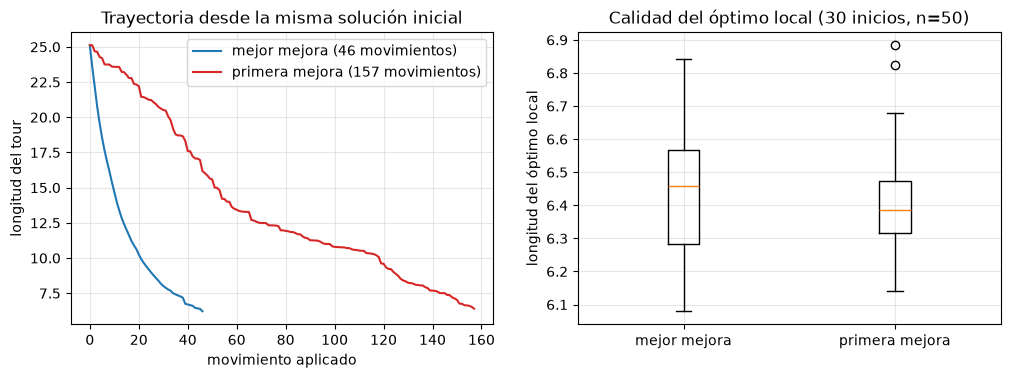

In [7]:
def ls_2opt_escalar(D, tour, estrategia="mejor", registrar=False):
    # 2-opt escalar. estrategia in {"mejor","primera"}. Devuelve (tour, costo, movimientos, evaluaciones, traza).
    Dl = D.tolist(); t = [int(x) for x in tour]; n = len(t); cost = float(longitud_tour(D, tour))
    movs = ev = 0; traza = [cost]
    while True:
        mejor = 0.0; mov = None
        for i in range(n - 2):
            a = t[i]; b = t[i + 1]; fila_a = Dl[a]; dab = fila_a[b]
            for j in range(i + 2, n if i > 0 else n - 1):
                c = t[j]; d = t[(j + 1) % n]; ev += 1
                dl = fila_a[c] + Dl[b][d] - dab - Dl[c][d]
                if dl < mejor - TOL:
                    mejor = dl; mov = (i, j)
                    if estrategia == "primera": break
            if estrategia == "primera" and mov is not None: break
        if mov is None: break
        i, j = mov; t[i + 1:j + 1] = t[i + 1:j + 1][::-1]; cost += mejor; movs += 1; traza.append(cost)
    t = np.array(t); assert es_permutacion(t, n) and abs(cost - longitud_tour(D, t)) < 1e-8
    return t, cost, movs, ev, traza

starts = [np.random.default_rng(100 + s).permutation(50) for s in range(30)]
res = {}
for est in ["mejor", "primera"]:
    t0 = time.perf_counter(); out = [ls_2opt_escalar(D50, s0, est) for s0 in starts]; dt = time.perf_counter() - t0
    res[est] = dict(costos=np.array([o[1] for o in out]), movs=np.array([o[2] for o in out]), evals=np.array([o[3] for o in out]), tiempo=dt / len(starts), traza=out[0][4])
print(f"{'estrategia':>10} {'costo medio':>12} {'costo mejor':>12} {'movs medios':>12} {'evals medias':>13} {'s/corrida':>10}")
for est, r_ in res.items():
    print(f"{est:>10} {r_['costos'].mean():12.3f} {r_['costos'].min():12.3f} {r_['movs'].mean():12.1f} {r_['evals'].mean():13.0f} {r_['tiempo']:10.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for est, col in [("mejor", "C0"), ("primera", "C3")]:
    axes[0].plot(res[est]["traza"], color=col, label=f"{est} mejora ({len(res[est]['traza'])-1} movimientos)")
axes[0].set_xlabel("movimiento aplicado"); axes[0].set_ylabel("longitud del tour"); axes[0].set_title("Trayectoria desde la misma solución inicial"); axes[0].legend()
axes[1].boxplot([res["mejor"]["costos"], res["primera"]["costos"]], tick_labels=["mejor mejora", "primera mejora"])
axes[1].set_ylabel("longitud del óptimo local"); axes[1].set_title("Calidad del óptimo local (30 inicios, n=50)"); plt.show()

Lectura de la tabla y la figura (cifras impresas arriba):
- **Primera mejora** aplica *muchos más* movimientos (pasos cortos, cada uno con una mejora pequeña) pero evalúa una cantidad de vecinos del mismo orden que la mejor mejora: cada barrido se interrumpe antes, aunque hay que hacer muchos más barridos parciales.
- **La calidad media del óptimo local es similar** en ambas estrategias; no hay un ganador claro en este tamaño. Las trayectorias (panel izquierdo) son distintas y terminan en óptimos locales distintos: la estrategia define *qué* valle se alcanza, no solo cuán rápido.
- En la práctica, la primera mejora con listas de vecinos (sección 7) es la preferida porque cada paso es muy barato y permite reaprovechar información local.

## 5. Comparación de vecindarios
Ahora comparamos swap, 2-opt, or-opt, la combinación 2-opt+or-opt (se aplica el primer vecindario que mejora, estilo *variable neighborhood descent*, ver [04](04-vns-lns.ipynb)) y 3-opt, con **mejor mejora** vectorizada desde las mismas 15 soluciones aleatorias en $n=50$. Los gaps se miden contra la cota de Held–Karp.

Cota de Held-Karp (n=50): 5.971   (gap contra la cota = techo del gap real)
       vecindario  costo_medio  costo_mejor   movs    evals   seg  gap_medio_%  gap_mejor_%
             swap        8.758        7.669 46.000  55225.0 0.023       46.671       28.435
            2-opt        6.453        6.241 45.400  54520.0 0.011        8.071        4.511
           or-opt        6.480        6.024 35.467 426660.0 0.072        8.527        0.880
   2-opt + or-opt        6.198        6.024 50.200 112420.0 0.021        3.799        0.880
3-opt (inserción)        6.421        6.185 36.200 729120.0 0.042        7.535        3.581


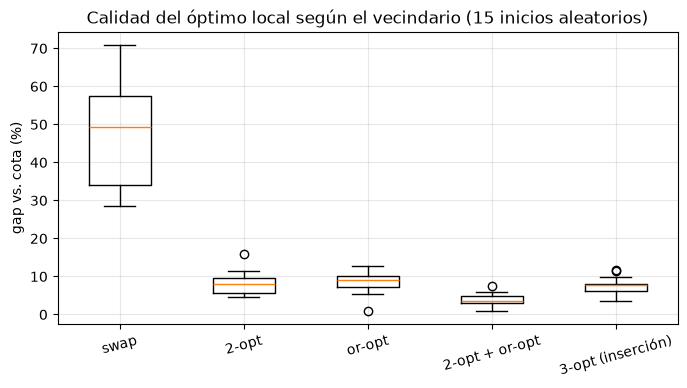

In [8]:
def busqueda_local(D, t, vecindarios):
    # vecindarios: lista de nombres en orden; aplica el mejor movimiento del primer vecindario que mejora (VND).
    t = t.copy(); cost = float(longitud_tour(D, t)); movs = ev = 0
    while True:
        for nombre in vecindarios:
            dl, mov, e = SCAN[nombre](D, t); ev += e
            if mov is not None:
                t = APLICAR[nombre](t, mov); cost += dl; movs += 1; break
        else:
            break
    assert es_permutacion(t, len(t)) and abs(cost - longitud_tour(D, t)) < 1e-8
    return t, cost, movs, ev

# referencia: cota de Held-Karp con UB = mejor de las corridas de abajo (se recalcula después)
configs = {"swap": ["swap"], "2-opt": ["2opt"], "or-opt": ["oropt"], "2-opt + or-opt": ["2opt", "oropt"], "3-opt (inserción)": ["3opt"]}
starts15 = [np.random.default_rng(200 + s).permutation(50) for s in range(15)]
filas = []; mejores = {}
for nombre, vec in configs.items():
    t0 = time.perf_counter(); out = [busqueda_local(D50, s0, vec) for s0 in starts15]; dt = (time.perf_counter() - t0) / len(starts15)
    c = np.array([o[1] for o in out]); mejores[nombre] = c
    filas.append(dict(vecindario=nombre, costo_medio=c.mean(), costo_mejor=c.min(), movs=np.mean([o[2] for o in out]), evals=np.mean([o[3] for o in out]), seg=dt))
UB50 = min(c.min() for c in mejores.values()); LB50 = cota_hk(D50, UB50)
tab = pd.DataFrame(filas); tab["gap_medio_%"] = gap(tab.costo_medio, LB50); tab["gap_mejor_%"] = gap(tab.costo_mejor, LB50)
print(f"Cota de Held-Karp (n=50): {LB50:.3f}   (gap contra la cota = techo del gap real)")
print(tab.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.boxplot([gap(mejores[k], LB50) for k in configs], tick_labels=list(configs)); ax.set_ylabel("gap vs. cota (%)")
ax.set_title("Calidad del óptimo local según el vecindario (15 inicios aleatorios)"); plt.xticks(rotation=15); plt.show()

Qué muestra la comparación (mira los gaps impresos):
- **Swap** es, con diferencia, el peor vecindario para el TSP aunque tenga el mismo tamaño que 2-opt: cambia 4 aristas por movimiento y rompe mucha estructura, así que casi cualquier movimiento empeora el tour y los óptimos locales son pobres. Coincide con lo visto en el paisaje exhaustivo de la notebook [01](../00-fundamentos/01-introduccion-optimizacion-combinatoria.ipynb): un vecindario poco "geométrico" produce un paisaje rugoso.
- **2-opt** y **or-opt** son vecindarios de calidad similar, pero or-opt requiere **muchas más evaluaciones** por pasada (columna `evals`). **3-opt** (en la variante de inserción de tramo) evalúa más aún y no supera claramente a la combinación sencilla.
- **2-opt + or-opt** (aplicar el primero que mejore) obtiene el mejor gap medio con un costo moderado: dos vecindarios complementarios producen óptimos locales respecto de *ambos*, que son mejores que respecto de cualquiera por separado. Esa es la semilla de la búsqueda de vecindario variable de [04 · VNS y LNS](04-vns-lns.ipynb).
- Un vecindario más grande no es automáticamente mejor: la relación calidad/costo importa, y la variabilidad entre inicios (cajas del gráfico) es grande, de modo que con 15 inicios hay que leer las diferencias pequeñas con cautela.

## 6. Evaluación incremental: cuánto cuesta no recalcular

Sin delta, evaluar un vecino exige construirlo y medir su longitud: $O(n)$. Un barrido de 2-opt cuesta entonces $O(n^2)\times O(n)=O(n^3)$. Con el delta de cuatro distancias, evaluar un vecino es $O(1)$ y el barrido completo es $O(n^2)$ (y el costo de *aplicar* el movimiento solo se paga **una vez por paso**, no por vecino).

Medimos el tiempo de **un barrido completo** del vecindario 2-opt con tres implementaciones: (i) ingenua (construir cada vecino y recalcular $f$), (ii) delta escalar en Python puro, (iii) delta vectorizado con NumPy. Se verifica que las tres encuentran el mismo mejor delta.

       ingenua O(n³)  delta escalar  delta vectorizado
n=50          0.0099         0.0001             0.0003
n=100         0.0359         0.0006             0.0005
n=200         0.1532         0.0022             0.0011
n=400            NaN         0.0132             0.0026
     ingenua O(n³): pendiente log-log ≈ 1.98
     delta escalar: pendiente log-log ≈ 2.14
 delta vectorizado: pendiente log-log ≈ 1.08


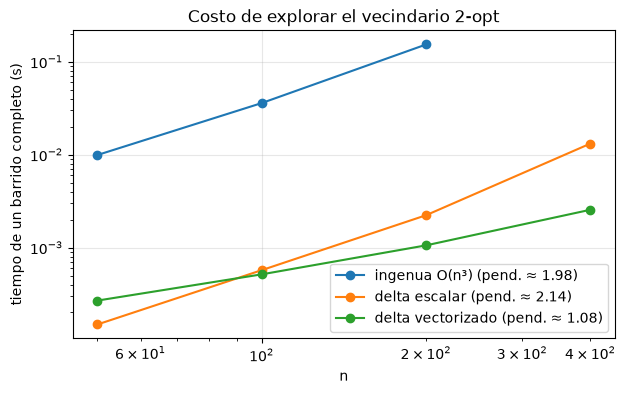

In [9]:
def barrido_ingenuo(D, t):
    n = len(t); base = longitud_tour(D, t); mejor = (0.0, None)
    for i in range(n - 2):
        for j in range(i + 2, n if i > 0 else n - 1):
            dl = longitud_tour(D, aplicar_2opt(t, (i, j))) - base
            if dl < mejor[0] - TOL: mejor = (dl, (i, j))
    return mejor[0], mejor[1]

def barrido_delta_escalar(D, t):
    n = len(t); Dl = D.tolist(); tl = t.tolist(); mejor = (0.0, None)
    for i in range(n - 2):
        a = tl[i]; b = tl[i + 1]; fa = Dl[a]; dab = fa[b]
        for j in range(i + 2, n if i > 0 else n - 1):
            c = tl[j]; d = tl[(j + 1) % n]; dl = fa[c] + Dl[b][d] - dab - Dl[c][d]
            if dl < mejor[0] - TOL: mejor = (dl, (i, j))
    return mejor

def medir(f, *args, reps=3):
    mejor_t = np.inf
    for _ in range(reps):
        t0 = time.perf_counter(); out = f(*args); mejor_t = min(mejor_t, time.perf_counter() - t0)
    return mejor_t, out

ns_t = [50, 100, 200, 400]; tiempos = {"ingenua O(n³)": [], "delta escalar": [], "delta vectorizado": []}
for n_ in ns_t:
    Dm = crear_tsp(n_, np.random.default_rng(n_))[1]; t = np.random.default_rng(1).permutation(n_)
    t_ing = np.nan; r1 = None
    if n_ <= 200:
        t_ing, r1 = medir(barrido_ingenuo, Dm, t, reps=1)
    t_esc, r2 = medir(barrido_delta_escalar, Dm, t); t_vec, r3 = medir(lambda D_, t_: scan_2opt(D_, t_)[:2], Dm, t)
    if r1 is not None: assert abs(r1[0] - r2[0]) < 1e-9 and r1[1] == r2[1]
    assert abs(r2[0] - r3[0]) < 1e-9
    tiempos["ingenua O(n³)"].append(t_ing); tiempos["delta escalar"].append(t_esc); tiempos["delta vectorizado"].append(t_vec)
print(pd.DataFrame(tiempos, index=[f"n={n_}" for n_ in ns_t]).round(4).to_string())
fig, ax = plt.subplots(figsize=(7, 4))
for k, v in tiempos.items():
    v = np.array(v); ok = ~np.isnan(v); pend = np.polyfit(np.log(np.array(ns_t)[ok]), np.log(v[ok]), 1)[0]
    print(f"{k:>18}: pendiente log-log ≈ {pend:.2f}")
    ax.loglog(np.array(ns_t)[ok], v[ok], "o-", label=f"{k} (pend. ≈ {pend:.2f})")
ax.set_xlabel("n"); ax.set_ylabel("tiempo de un barrido completo (s)"); ax.set_title("Costo de explorar el vecindario 2-opt"); ax.legend(); plt.show()

Lo que dicen las cifras (tabla y pendientes log–log impresas):
- La versión **ingenua** es del orden de **decenas de veces más lenta** que el delta escalar en todos los tamaños probados, aunque produce exactamente el mismo mejor movimiento (los `assert` lo comprueban).
- Teóricamente la ingenua escala como $n^3$ y la de delta como $n^2$. La pendiente medida del delta escalar ($\approx 2$) concuerda con la teoría; la de la ingenua sale menor que 3 porque, a estos tamaños, recomputar $f$ con NumPy está dominado por el costo fijo de cada llamada (unos microsegundos) y no por los $n$ elementos. A $n$ mayor la brecha se ensancharía.
- La versión vectorizada es la más rápida, pero su pendiente (menor) refleja sobre todo el costo fijo de las llamadas a NumPy por fila.
- Conclusión: **calcular deltas es la primera optimización obligatoria**.

## 7. Listas de vecinos y *don't-look bits*

Incluso con delta $O(1)$, un barrido completo cuesta $\Theta(n^2)$ y hay que repetirlo muchas veces. Dos ideas clásicas lo reducen drásticamente (Bentley, 1992; Johnson & McGeoch, 1997):

**Listas de vecinos (*neighbor lists*).** Para cada ciudad $a$ guardamos sus $K$ vecinas más cercanas. Para un movimiento 2-opt que reemplaza $(a,b),(c,d)$ por $(a,c),(b,d)$, un movimiento **mejora solo si** $d_{ac}<d_{ab}$ o $d_{bd}<d_{cd}$. Por eso basta, para cada $a$, recorrer sus vecinas $c$ en orden creciente de distancia y **cortar** en cuanto $d_{ac}\ge d_{ab}$. Se prueban ambas orientaciones (sucesor y predecesor de $a$). Con $K=n-1$ la exploración es *exacta* (mismo vecindario completo); con $K$ pequeño es una poda heurística.

**Don't-look bits.** Si ninguna arista incidente en la ciudad $a$ ha cambiado desde la última vez que se la examinó sin éxito, volver a examinarla es inútil. Mantenemos una cola de ciudades "activas": solo se procesan esas, y tras aplicar un movimiento se reactivan las 4 ciudades extremo. Esto hace que, tras una perturbación local (ILS), solo se revisen las pocas ciudades afectadas.

**Representación.** Mantenemos `tour` y `pos` (posición de cada ciudad) para consultar sucesor/predecesor en $O(1)$. Invertir el tramo $b..c$ cuesta su longitud; se invierte el **lado más corto** del ciclo (equivalente porque el ciclo no cambia, solo su orientación).

```
cola ← todas las ciudades (o solo las afectadas)
mientras cola no vacía:
    a ← sacar(cola)
    repetir:
        para sentido ∈ {sucesor, predecesor}:
            b ← vecina de a en ese sentido
            para c ∈ vecinas(a) en orden creciente:
                si d(a,c) ≥ d(a,b): romper
                d ← vecina de c en el mismo sentido
                si Δ = d(a,c)+d(b,d)-d(a,b)-d(c,d) < 0:
                    aplicar; encolar a, b, c, d; reiniciar con a
        hasta que no haya mejora para a
```

In [10]:
def crear_instancia(D, K):
    # Empaqueta la matriz, su copia en listas (acceso rápido en Python) y las K vecinas más cercanas de cada ciudad.
    return dict(D=D, Dl=D.tolist(), vec=np.argsort(D, axis=1)[:, 1:K + 1].tolist())

def ls_2opt_dlb(inst, tour, activos=None, costo=None):
    # 2-opt con listas de vecinos + don't-look bits (cola de ciudades activas). Devuelve (tour, costo).
    D, Dl, vec = inst["D"], inst["Dl"], inst["vec"]
    t = [int(x) for x in tour]; n = len(t); pos = [0] * n
    for i, c in enumerate(t): pos[c] = i
    cost = float(longitud_tour(D, tour)) if costo is None else float(costo)
    cola = deque(t if activos is None else activos); en = [False] * n
    for c in cola: en[c] = True

    def invertir(i, j):
        # Invierte el tramo cíclico de posiciones i..j (inclusive); si es más largo que n/2, invierte el complemento.
        L = (j - i) % n + 1
        if 2 * L > n: i, j, L = (j + 1) % n, (i - 1) % n, n - L
        for k in range(L // 2):
            a = (i + k) % n; b = (j - k) % n
            t[a], t[b] = t[b], t[a]; pos[t[a]] = a; pos[t[b]] = b

    while cola:
        a = cola.popleft(); en[a] = False
        mejorado = True
        while mejorado:
            mejorado = False; i = pos[a]; fila = Dl[a]
            for sentido in (0, 1):
                b = t[(i + 1) % n] if sentido == 0 else t[(i - 1) % n]; dab = fila[b]
                for c in vec[a]:
                    dac = fila[c]
                    if dac >= dab - TOL: break
                    j = pos[c]; d = t[(j + 1) % n] if sentido == 0 else t[(j - 1) % n]
                    if c == b or d == a: continue
                    dl = dac + Dl[b][d] - dab - Dl[c][d]
                    if dl < -TOL:
                        if sentido == 0: invertir((i + 1) % n, j)
                        else: invertir(i, (j - 1) % n)
                        cost += dl
                        for x in (b, c, d):
                            if not en[x]: cola.append(x); en[x] = True
                        mejorado = True; break
                if mejorado: break
    t = np.array(t); return t, cost

# Verificación: tour válido, costo acumulado == recomputación, y con K=n-1 es óptimo local EXACTO respecto de 2-opt completo
Dv = crear_tsp(60, np.random.default_rng(3))[1]; inst_v = crear_instancia(Dv, 59)
for s in range(20):
    t_v, c_v = ls_2opt_dlb(inst_v, np.random.default_rng(s).permutation(60))
    assert es_permutacion(t_v, 60) and abs(c_v - longitud_tour(Dv, t_v)) < 1e-8
    assert scan_2opt(Dv, t_v)[1] is None
print("20 búsquedas verificadas: tour válido, costo consistente y óptimo local exacto de 2-opt (K=n-1).")

20 búsquedas verificadas: tour válido, costo consistente y óptimo local exacto de 2-opt (K=n-1).


Comparamos tres implementaciones de 2-opt desde la **misma solución inicial** (vecino más cercano) en $n=200$: mejor mejora vectorizada con barrido completo, primera mejora escalar (barrido completo) y listas de vecinos ($K=10$) con don't-look bits. Luego $n=1000$ solo con la versión rápida.

In [11]:
def comparar_2opt(n_, K=10, completas=True):
    Dm = crear_tsp(n_, np.random.default_rng(900 + n_))[1]; t0_ = vecino_mas_cercano(Dm, 0); f0 = longitud_tour(Dm, t0_); out = {}
    if completas:
        t0 = time.perf_counter(); t1, c1, m1, e1 = busqueda_local(Dm, t0_, ["2opt"]); out["mejor mejora vectorizada"] = (c1, time.perf_counter() - t0)
        t0 = time.perf_counter(); t2, c2, m2, e2, _ = ls_2opt_escalar(Dm, t0_, "primera"); out["primera mejora escalar"] = (c2, time.perf_counter() - t0)
    inst = crear_instancia(Dm, K)
    t0 = time.perf_counter(); t3, c3 = ls_2opt_dlb(inst, t0_); dt = time.perf_counter() - t0
    assert es_permutacion(t3, n_) and abs(c3 - longitud_tour(Dm, t3)) < 1e-8
    out[f"listas de vecinos K={K} + DLB"] = (c3, dt)
    resto = scan_2opt(Dm, t3)[0]
    return f0, out, resto

for n_ in [200, 1000]:
    f0, out, resto = comparar_2opt(n_, completas=(n_ == 200))
    print(f"\nn={n_}: NN inicial = {f0:.3f}")
    for k, (c, dt) in out.items(): print(f"  {k:<30} costo final = {c:9.3f}   tiempo = {dt:7.3f} s")
    print(f"  mejora residual que aún permite un barrido 2-opt completo tras la versión con listas: {resto:.5f} (0 = óptimo local exacto)")


n=200: NN inicial = 13.894
  mejor mejora vectorizada       costo final =    11.328   tiempo =   0.040 s
  primera mejora escalar         costo final =    11.839   tiempo =   0.084 s
  listas de vecinos K=10 + DLB   costo final =    11.510   tiempo =   0.001 s
  mejora residual que aún permite un barrido 2-opt completo tras la versión con listas: 0.00000 (0 = óptimo local exacto)



n=1000: NN inicial = 28.716
  listas de vecinos K=10 + DLB   costo final =    24.788   tiempo =   0.004 s
  mejora residual que aún permite un barrido 2-opt completo tras la versión con listas: -0.03325 (0 = óptimo local exacto)


Observaciones (cifras impresas arriba):
- Con $K=10$ y *don't-look bits*, la búsqueda tarda **milésimas de segundo** donde las versiones de barrido completo tardan decenas o cientos de milisegundos ($n=200$), y para $n=1000$ sigue siendo una fracción de segundo; el costo pasa de $\Theta(n^2)$ por barrido a algo cercano a *lineal en las ciudades afectadas*.
- La calidad final es comparable a la de los barridos completos (puede ser algo mejor o peor según el camino seguido). La **poda** con $K$ pequeño puede dejar movimientos mejorantes sin explorar: en $n=1000$ el barrido completo aún encuentra una mejora residual (impresa), mientras que en $n=200$ el resultado coincide con un óptimo local exacto. Con $K=n-1$ es exacto (verificado con `assert`).
- Esto es lo que hace práctica a la ILS: tras una perturbación solo hay que reexaminar unas pocas ciudades, no recorrer todo el vecindario.

## 8. Óptimos locales y estructura del paisaje

Si los óptimos locales de un TSP fueran puntos arbitrarios del espacio, no habría nada que explotar. Pero empíricamente (Boese, Kahng & Muddu, 1994) los óptimos locales de buena calidad se **agrupan**: están relativamente cerca unos de otros y del óptimo global, formando un "gran valle" (*big valley*). Medimos esa estructura con la **distancia de aristas** entre tours (aristas de un tour ausentes en el otro).

Procedimiento en $n=60$:
1. Obtener una solución de referencia $x^\star$ muy buena (una ILS larga, sección 9; aquí usamos una versión compacta).
2. Generar 400 óptimos locales exactos de 2-opt desde inicios aleatorios.
3. Graficar costo vs. distancia a $x^\star$ y medir su correlación; comparar con la distancia entre tours aleatorios.

La función de **perturbación** y la ILS completa se explican en la sección 9; aquí solo usamos una versión mínima para obtener $x^\star$.

referencia x*: 5.9126 (ILS básica, 3000 iter., 0.2s)
óptimos locales distintos entre 400 inicios: 391
costo medio de los óptimos locales = 6.220 | x* = 5.913 | mejor óptimo local hallado = 5.939
distancia media (en aristas) entre dos óptimos locales = 17.8 | entre dos tours aleatorios = 57.8 (de n=60)
correlación costo - distancia a x*: 0.435


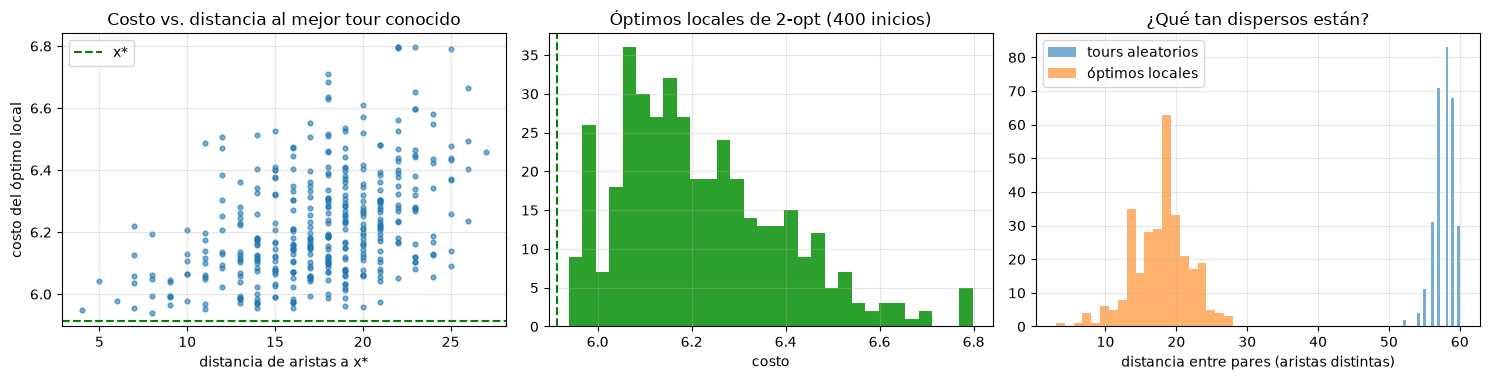

In [12]:
def doble_puente(t, r):
    # Doble puente (4 aristas): A B C D -> A D C B con 3 cortes aleatorios. Devuelve (tour_nuevo, ciudades_tocadas).
    n = len(t); p1, p2, p3 = np.sort(r.choice(np.arange(1, n), 3, replace=False))
    nuevo = np.concatenate([t[:p1], t[p3:], t[p2:p3], t[p1:p2]])
    tocadas = [t[p1 - 1], t[p3], t[n - 1], t[p2], t[p3 - 1], t[p1], t[p2 - 1], t[0]]
    return nuevo, [int(x) for x in tocadas]

def ils_basica(inst, iters, r, t0=None):
    # ILS mínima: doble puente + 2-opt/DLB + aceptar solo si mejora.
    D = inst["D"]; n = len(D); t = vecino_mas_cercano(D, 0) if t0 is None else t0
    t, c = ls_2opt_dlb(inst, t); mejor, cm = t.copy(), c
    for _ in range(iters):
        u, tocadas = doble_puente(t, r); cu = longitud_tour(D, u); u, cu = ls_2opt_dlb(inst, u, tocadas, cu)
        if cu < c - TOL: t, c = u, cu
        if c < cm - TOL: mejor, cm = t.copy(), c
    assert es_permutacion(mejor, n) and abs(cm - longitud_tour(D, mejor)) < 1e-8
    return mejor, cm

N8 = 60; pts60, D60 = crear_tsp(N8, np.random.default_rng(21)); inst60 = crear_instancia(D60, N8 - 1)
t0 = time.perf_counter(); x_ref, f_ref = ils_basica(inst60, 3000, np.random.default_rng(0)); print(f"referencia x*: {f_ref:.4f} (ILS básica, 3000 iter., {time.perf_counter()-t0:.1f}s)")

R = 400; rs = np.random.default_rng(1); optimos = []; costos_lo = []
for _ in range(R):
    t_, c_ = ls_2opt_dlb(inst60, rs.permutation(N8)); optimos.append(t_); costos_lo.append(c_)
costos_lo = np.array(costos_lo); d_ref = np.array([dist_aristas(o, x_ref) for o in optimos])
distintos = len({frozenset(aristas(o)) for o in optimos})
d_pares = [dist_aristas(optimos[i], optimos[j]) for i, j in rs.integers(0, R, (300, 2)) if i != j]
d_alea = [dist_aristas(rs.permutation(N8), rs.permutation(N8)) for _ in range(300)]
print(f"óptimos locales distintos entre {R} inicios: {distintos}")
print(f"costo medio de los óptimos locales = {costos_lo.mean():.3f} | x* = {f_ref:.3f} | mejor óptimo local hallado = {costos_lo.min():.3f}")
print(f"distancia media (en aristas) entre dos óptimos locales = {np.mean(d_pares):.1f} | entre dos tours aleatorios = {np.mean(d_alea):.1f} (de n={N8})")
print(f"correlación costo - distancia a x*: {np.corrcoef(costos_lo, d_ref)[0, 1]:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
axes[0].scatter(d_ref, costos_lo, s=12, alpha=0.6); axes[0].axhline(f_ref, color="g", ls="--", label="x*")
axes[0].set_xlabel("distancia de aristas a x*"); axes[0].set_ylabel("costo del óptimo local"); axes[0].set_title("Costo vs. distancia al mejor tour conocido"); axes[0].legend()
axes[1].hist(costos_lo, bins=30, color="C2"); axes[1].axvline(f_ref, color="g", ls="--"); axes[1].set_xlabel("costo"); axes[1].set_title("Óptimos locales de 2-opt (400 inicios)")
axes[2].hist(d_alea, bins=20, alpha=0.6, label="tours aleatorios"); axes[2].hist(d_pares, bins=20, alpha=0.6, label="óptimos locales"); axes[2].set_xlabel("distancia entre pares (aristas distintas)"); axes[2].legend(); axes[2].set_title("¿Qué tan dispersos están?")
plt.tight_layout(); plt.show()

Qué se ve (cifras y figura de arriba):
- Los 400 inicios producen **casi 400 óptimos locales distintos**: el número de óptimos locales es enorme incluso para $n=60$, de modo que un reinicio aleatorio rara vez repite valle.
- Pero no están dispersos al azar. Dos óptimos locales difieren en **muchas menos aristas** que dos tours aleatorios (tercer panel): comparten gran parte de la estructura; y hay una **correlación positiva** entre el costo de un óptimo local y su distancia al mejor tour conocido (primer panel): los mejores óptimos locales están más cerca de $x^\star$. Es la estructura de "gran valle".
- **Consecuencia algorítmica:** conviene *moverse entre óptimos locales cercanos* (perturbaciones moderadas) y no reiniciar desde cero, porque buenos óptimos locales suelen encontrarse cerca de otros buenos. Es el fundamento de la ILS (y de otras como VNS y *path relinking*). La estructura depende de la instancia y del vecindario, y no siempre es tan nítida (p. ej. en instancias con estructura distinta).

## 9. Perturbación e *Iterated Local Search*

La **ILS** (Lourenço, Martin & Stützle, 2003) es el esqueleto más simple para *escapar* de los óptimos locales sin tirar el progreso:

```
s0 ← solución_inicial
s  ← BúsquedaLocal(s0);  s* ← s
repetir:
    s'  ← Perturbar(s, historia)         # salto moderado: sale de la cuenca actual
    s'' ← BúsquedaLocal(s')              # cae en un (otro) óptimo local
    s   ← Aceptar(s, s'', historia)      # criterio de aceptación
    si f(s) < f(s*): s* ← s
```

Es un **paseo aleatorio sobre óptimos locales**: el espacio efectivo de búsqueda no es $X$, sino $X^{\text{LO}}$ (el conjunto de óptimos locales), mucho más pequeño. Cuatro componentes: solución inicial, búsqueda local, **perturbación** y **criterio de aceptación**.

### Perturbaciones
La perturbación debe ser **lo bastante fuerte para que la búsqueda local no la deshaga** (si el 2-opt la revierte en un paso, volvemos al mismo óptimo local) y **lo bastante débil para conservar la estructura buena** de $s$ (si es demasiado fuerte, ILS degenera en reinicios aleatorios).

| Perturbación | Aristas cambiadas | ¿La deshace 2-opt en un paso? |
|---|---|---|
| Reversión aleatoria (un 2-opt aleatorio) | 2 | **Sí**, inmediatamente |
| Intercambio de tramos adyacentes ($A\,C\,B\,D$) | 3 | No con 2-opt (sí con 3-opt de inserción de tramo) |
| **Doble puente** ($A\,D\,C\,B$) | **4** (3 en casos degenerados con un tramo de 1 ciudad) | No (movimiento no secuencial) |
| $k$ dobles puentes consecutivos | hasta $4k$ | No |
| Doble puente **local** (cortes dentro de una ventana de $w$ posiciones) | 4, todas cerca | No; no destruye lo lejano |

El **doble puente** (Martin, Otto & Felten, 1991) es el estándar con 2-opt/3-opt/Lin–Kernighan porque estos no pueden deshacerlo fácilmente. Dos precisiones: llamamos "doble puente" a $A\,D\,C\,B$ porque *cambia 4 aristas* (con dos "puentes" sucesivos: dos cortes que reconectan sin invertir y crean dos ciclos, y otros dos que los vuelven a unir), mientras que la versión muy difundida $A\,C\,B\,D$ cambia a lo sumo 3 (el cierre $D\to A$ se conserva), es decir, intercambia dos tramos adyacentes. El conteo de aristas se verifica en la celda siguiente (los mínimos menores corresponden a casos degenerados con tramos de una sola ciudad). Y para instancias grandes conviene la versión **local**, que mantiene el cambio acotado a una zona del tour (con *don't-look bits* solo se reexaminan las 8 ciudades tocadas).

In [13]:
def intercambio_tramos(t, r):
    # A B C D -> A C B D (cambia 3 aristas; es una inserción de tramo)
    n = len(t); p1, p2, p3 = np.sort(r.choice(np.arange(1, n), 3, replace=False))
    nuevo = np.concatenate([t[:p1], t[p2:p3], t[p1:p2], t[p3:]])
    return nuevo, [int(x) for x in (t[p1 - 1], t[p2], t[p3 - 1], t[p1], t[p2 - 1], t[p3])]

def reversion_aleatoria(t, r):
    # Un movimiento 2-opt aleatorio (2 aristas)
    n = len(t); i, j = np.sort(r.choice(np.arange(1, n), 2, replace=False)); nuevo = t.copy(); nuevo[i:j + 1] = nuevo[i:j + 1][::-1]
    return nuevo, [int(x) for x in (t[i - 1], t[i], t[j], t[(j + 1) % n])]

def k_dobles_puentes(t, r, k):
    tocadas = []
    for _ in range(k):
        t, tc = doble_puente(t, r); tocadas += tc
    return t, tocadas

def doble_puente_local(t, r, w):
    # Doble puente con los 3 cortes dentro de una ventana de w posiciones consecutivas (rotando el tour).
    n = len(t); s = int(r.integers(n)); tr = np.roll(t, -s); w = min(w, n - 1)
    nuevo, tocadas = doble_puente_ventana(tr, r, w); return nuevo, tocadas

def doble_puente_ventana(tr, r, w):
    n = len(tr); p1, p2, p3 = np.sort(r.choice(np.arange(1, w + 1), 3, replace=False))
    nuevo = np.concatenate([tr[:p1], tr[p3:], tr[p2:p3], tr[p1:p2]])
    return nuevo, [int(x) for x in (tr[p1 - 1], tr[p3], tr[n - 1], tr[p2], tr[p3 - 1], tr[p1], tr[p2 - 1], tr[0])]

# Verificación: validez y número de aristas cambiadas
r = np.random.default_rng(3); n_p = 40; base = r.permutation(n_p)
perts = {"reversión aleatoria": reversion_aleatoria, "intercambio de tramos (A C B D)": intercambio_tramos, "doble puente (A D C B)": doble_puente,
         "doble puente local (w=10)": lambda t, r_: doble_puente_local(t, r_, 10)}
for nombre, f in perts.items():
    cambios = []
    for _ in range(300):
        u, tc = f(base, r); assert es_permutacion(u, n_p)
        cambios.append(n_p - len(aristas(u) & aristas(base)))
    print(f"{nombre:<34} aristas cambiadas: mín={min(cambios)}, máx={max(cambios)}")

reversión aleatoria                aristas cambiadas: mín=2, máx=2
intercambio de tramos (A C B D)    aristas cambiadas: mín=2, máx=3
doble puente (A D C B)             aristas cambiadas: mín=3, máx=4
doble puente local (w=10)          aristas cambiadas: mín=2, máx=4


n=200  NN=13.776 | 2-opt (desde NN)=11.890 | ILS 6000 iter.=11.024 (0.7s) | cota HK=10.914
gap vs. cota: NN 26.2 % | 2-opt 8.9 % | ILS 1.0 %


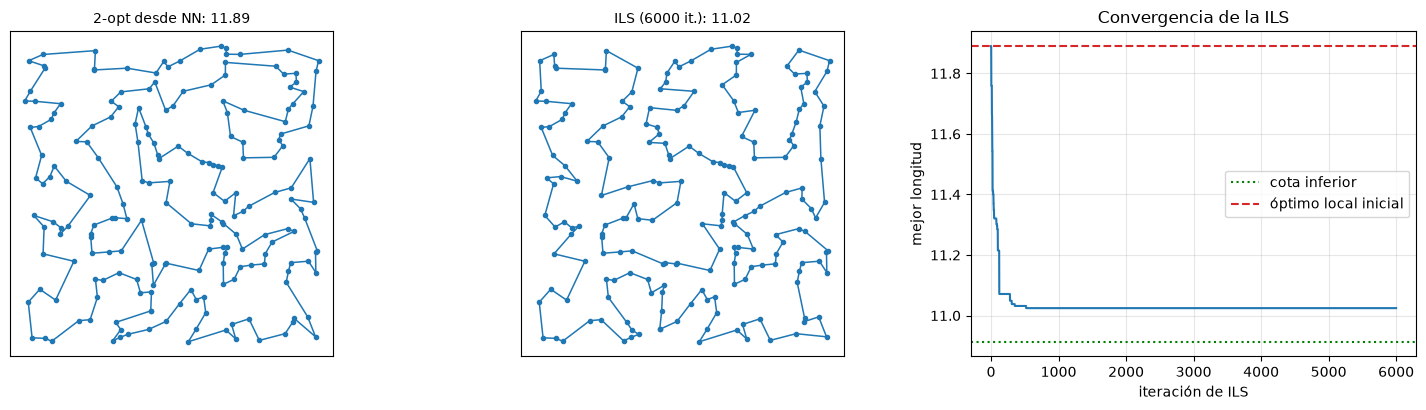

In [14]:
def ils(inst, iters, perturbar, aceptacion, r, tau=0.1, t0=None, paciencia=500, devolver_traza=False):
    # ILS con criterios de aceptación: "mejor" (solo si mejora), "mejor_o_igual", "siempre" (paseo aleatorio sobre óptimos locales),
    # "metropolis" (temperatura T = tau * longitud_media_de_arista), "reinicio" (como "mejor" pero reinicia tras 'paciencia' iteraciones sin mejorar).
    D = inst["D"]; n = len(D)
    t = vecino_mas_cercano(D, 0) if t0 is None else t0
    t, c = ls_2opt_dlb(inst, t); mejor, cm = t.copy(), c; T = tau * c / n; sin_mejora = 0; traza = np.empty(iters)
    for it in range(iters):
        u, tocadas = perturbar(t, r); cu = longitud_tour(D, u); u, cu = ls_2opt_dlb(inst, u, tocadas, cu)
        if aceptacion == "mejor": ok = cu < c - TOL
        elif aceptacion == "mejor_o_igual": ok = cu <= c + TOL
        elif aceptacion == "siempre": ok = True
        elif aceptacion == "metropolis": ok = cu < c or r.random() < math.exp(-(cu - c) / T)
        else: ok = cu < c - TOL
        if ok: t, c = u, cu
        if c < cm - TOL: mejor, cm = t.copy(), c; sin_mejora = 0
        else: sin_mejora += 1
        if aceptacion == "reinicio" and sin_mejora >= paciencia:
            t, c = ls_2opt_dlb(inst, r.permutation(n)); sin_mejora = 0
        traza[it] = cm
    assert es_permutacion(mejor, n) and abs(cm - longitud_tour(D, mejor)) < 1e-8
    return (mejor, cm, traza) if devolver_traza else (mejor, cm)

# Demostración en n=200
N1 = 200; pts100, D100 = crear_tsp(N1, np.random.default_rng(31)); inst100 = crear_instancia(D100, 12)
t_nn = vecino_mas_cercano(D100, 0); t_ls, c_ls = ls_2opt_dlb(inst100, t_nn)
t0 = time.perf_counter(); t_ils, c_ils, tr_ils = ils(inst100, 6000, doble_puente, "mejor", np.random.default_rng(0), devolver_traza=True); dt = time.perf_counter() - t0
UB100 = c_ils; LB100 = cota_hk(D100, UB100)
print(f"n=200  NN={longitud_tour(D100, t_nn):.3f} | 2-opt (desde NN)={c_ls:.3f} | ILS 6000 iter.={c_ils:.3f} ({dt:.1f}s) | cota HK={LB100:.3f}")
print(f"gap vs. cota: NN {gap(longitud_tour(D100, t_nn), LB100):.1f} % | 2-opt {gap(c_ls, LB100):.1f} % | ILS {gap(c_ils, LB100):.1f} %")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
graficar_tour(pts100, t_ls, axes[0], f"2-opt desde NN: {c_ls:.2f}"); graficar_tour(pts100, t_ils, axes[1], f"ILS (6000 it.): {c_ils:.2f}")
axes[2].plot(tr_ils); axes[2].axhline(LB100, color="g", ls=":", label="cota inferior"); axes[2].axhline(c_ls, color="C3", ls="--", label="óptimo local inicial")
axes[2].set_xlabel("iteración de ILS"); axes[2].set_ylabel("mejor longitud"); axes[2].set_title("Convergencia de la ILS"); axes[2].legend()
plt.tight_layout(); plt.show()

## 10. Criterios de aceptación

El criterio de aceptación regula el equilibrio intensificación/diversificación **a nivel de óptimos locales**:

| Criterio | Regla | Comportamiento |
|---|---|---|
| **Mejor** | aceptar $s''$ solo si $f(s'')<f(s)$ | intensificación fuerte; riesgo de estancamiento |
| **Siempre** (*random walk*) | aceptar siempre | diversificación total; pierde el progreso |
| **Metropolis** (LSMC; Martin et al., 1991) | si $\Delta>0$ aceptar con prob. $e^{-\Delta/T}$ | intermedio; $T$ controla el balance |
| **Reinicio** | como "mejor", pero reinicia desde una solución aleatoria tras $r=500$ iteraciones sin mejora | diversificación por saltos grandes |

Los comparamos con el **mismo número de iteraciones** (6000), el mismo doble puente y 5 semillas por configuración sobre la instancia de $n=200$. Los gaps son contra la cota de Held–Karp.

(24s) cota de Held-Karp = 10.914
            criterio  gap medio %  gap mejor %  gap peor %
               mejor         0.96         0.32        2.06
             siempre         2.60         2.17        2.94
   metropolis τ=0.02         0.92         0.32        1.48
    metropolis τ=0.1         0.83         0.50        1.33
    metropolis τ=0.5         0.67         0.51        0.83
    reinicio (r=500)         0.60         0.50        0.66


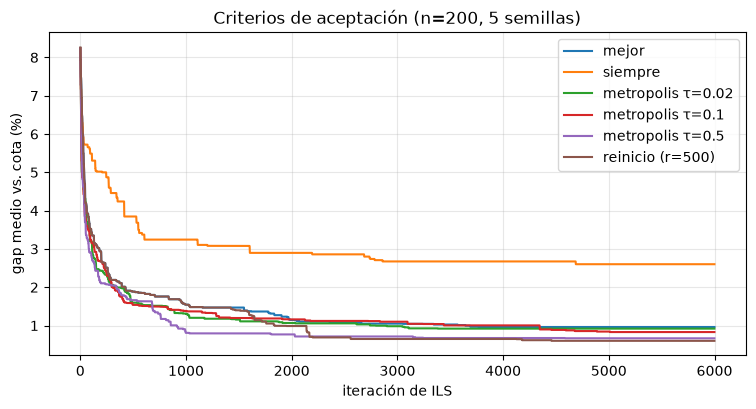

In [15]:
ITERS = 6000; SEM = 5
cfg_acep = [("mejor", "mejor", 0.0), ("siempre", "siempre", 0.0), ("metropolis τ=0.02", "metropolis", 0.02), ("metropolis τ=0.1", "metropolis", 0.1),
            ("metropolis τ=0.5", "metropolis", 0.5), ("reinicio (r=500)", "reinicio", 0.0)]
res_ac = {}; t0 = time.perf_counter()
for nombre, acep, tau in cfg_acep:
    res_ac[nombre] = np.array([ils(inst100, ITERS, doble_puente, acep, np.random.default_rng(10 + s), tau=tau, devolver_traza=True)[2] for s in range(SEM)])
print(f"({time.perf_counter()-t0:.0f}s) cota de Held-Karp = {LB100:.3f}")
print(f"{'criterio':>20} {'gap medio %':>12} {'gap mejor %':>12} {'gap peor %':>11}")
for nombre, tr in res_ac.items():
    f = tr[:, -1]; print(f"{nombre:>20} {gap(f.mean(), LB100):12.2f} {gap(f.min(), LB100):12.2f} {gap(f.max(), LB100):11.2f}")

fig, ax = plt.subplots(figsize=(9, 4.2))
for nombre, tr in res_ac.items(): ax.plot(gap(tr.mean(axis=0), LB100), label=nombre)
ax.set_xlabel("iteración de ILS"); ax.set_ylabel("gap medio vs. cota (%)"); ax.set_title("Criterios de aceptación (n=200, 5 semillas)"); ax.set_ylim(top=gap(res_ac["mejor"][:, 0].mean(), LB100) * 1.05); ax.legend(); plt.show()

Resultados (cifras impresas; ojo: con 5 semillas la variabilidad es alta y diferencias pequeñas no son concluyentes):
- **"Siempre aceptar"** (paseo aleatorio sobre óptimos locales) es claramente la peor: pierde lo ganado y solo explota la perturbación; queda muy por detrás de los demás criterios (aunque aún por debajo del óptimo local inicial, porque guardamos el mejor visto).
- **"Solo mejora"** converge rápido pero es la que tiene más variabilidad entre semillas (algunas se estancan antes). Los criterios que **inyectan algo de diversificación** (Metropolis con temperatura moderada, reinicio tras estancamiento) obtienen mejor gap medio y menor dispersión en esta instancia, con el mismo número de iteraciones.
- La temperatura de Metropolis es un parámetro sensible: demasiado baja ($\tau=0.02$) se comporta casi como "solo mejora"; muy alta se acercaría a "siempre". Lo razonable es calibrar $\tau$ (notebook [15](../05-evaluacion-y-ajuste/15-ajuste-de-parametros.ipynb)).
- No hay un criterio universal: la mejor opción depende del presupuesto (con pocas iteraciones intensificar, con muchas diversificar).

## 11. Fuerza de la perturbación

Fijamos la aceptación "mejor" y variamos la perturbación: reversión aleatoria (una arista de 2-opt, que 2-opt deshace), intercambio de tramos (3 aristas), $k=1,2,4,8$ dobles puentes **globales**, y dobles puentes **locales** con ventanas $w=10,30$. Mismo presupuesto de 6000 iteraciones; 5 semillas. Registramos también el **tiempo** (las perturbaciones fuertes obligan a la búsqueda local a trabajar más).

                    perturbación  gap medio %  gap mejor %  s/corrida
 reversión aleatoria (2 aristas)         1.55         0.64       0.32
       intercambio de tramos (3)         1.06         0.73       0.52
                doble puente k=1         0.77         0.60       0.71
                doble puente k=2         0.58         0.32       1.09
                doble puente k=4         0.61         0.52       1.87
                doble puente k=8         0.67         0.47       3.44
         doble puente local w=10         2.43         1.89       0.49
         doble puente local w=30         1.35         0.89       0.55


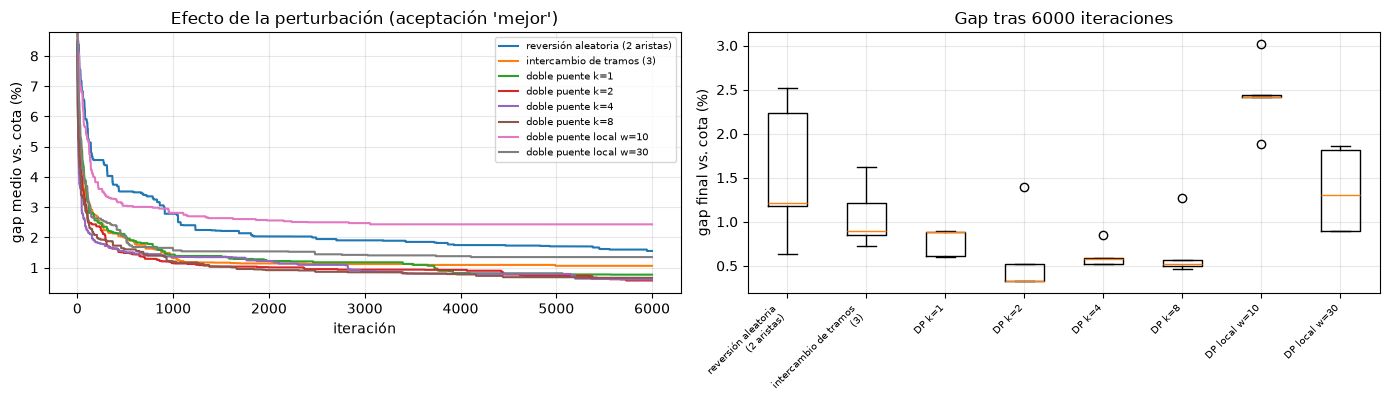

In [16]:
cfg_pert = [("reversión aleatoria (2 aristas)", reversion_aleatoria), ("intercambio de tramos (3)", intercambio_tramos),
            ("doble puente k=1", lambda t, r_: k_dobles_puentes(t, r_, 1)), ("doble puente k=2", lambda t, r_: k_dobles_puentes(t, r_, 2)),
            ("doble puente k=4", lambda t, r_: k_dobles_puentes(t, r_, 4)), ("doble puente k=8", lambda t, r_: k_dobles_puentes(t, r_, 8)),
            ("doble puente local w=10", lambda t, r_: doble_puente_local(t, r_, 10)), ("doble puente local w=30", lambda t, r_: doble_puente_local(t, r_, 30))]
res_pt = {}; tiempos_pt = {}
for nombre, f in cfg_pert:
    t0 = time.perf_counter()
    res_pt[nombre] = np.array([ils(inst100, ITERS, f, "mejor", np.random.default_rng(20 + s), devolver_traza=True)[2] for s in range(SEM)])
    tiempos_pt[nombre] = (time.perf_counter() - t0) / SEM
print(f"{'perturbación':>32} {'gap medio %':>12} {'gap mejor %':>12} {'s/corrida':>10}")
for nombre, tr in res_pt.items():
    f = tr[:, -1]; print(f"{nombre:>32} {gap(f.mean(), LB100):12.2f} {gap(f.min(), LB100):12.2f} {tiempos_pt[nombre]:10.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for nombre, tr in res_pt.items(): axes[0].plot(gap(tr.mean(axis=0), LB100), label=nombre)
axes[0].set_xlabel("iteración"); axes[0].set_ylabel("gap medio vs. cota (%)"); axes[0].set_title("Efecto de la perturbación (aceptación 'mejor')"); axes[0].legend(fontsize=7)
axes[0].set_ylim(top=gap(res_pt["doble puente k=1"][:, 0].mean(), LB100) * 1.05)
axes[1].boxplot([gap(res_pt[k][:, -1], LB100) for k in res_pt], tick_labels=[k.replace("doble puente", "DP").replace(" (", "\n(") for k in res_pt]); plt.setp(axes[1].get_xticklabels(), rotation=45, ha="right", fontsize=7)
axes[1].set_ylabel("gap final vs. cota (%)"); axes[1].set_title("Gap tras 6000 iteraciones"); plt.tight_layout(); plt.show()

Lectura (cifras y figuras de arriba; 5 semillas, con ruido):
- **Perturbación demasiado débil** (una reversión aleatoria o un doble puente restringido a una ventana de 10 posiciones) rinde peor: probablemente la búsqueda local la deshace con facilidad o el salto es tan pequeño que se vuelve a caer en el mismo óptimo local. Es el caso "muy intensificado".
- **Perturbación moderada** (uno a pocos dobles puentes globales) da los mejores gaps medios. Con **$k$ grande** el costo por iteración sube mucho (la búsqueda local tiene que reparar más) y el beneficio deja de crecer: hay un óptimo de compromiso, no un "más fuerte es mejor".
- El **doble puente local** con ventana intermedia ($w=30$) mejora a la ventana pequeña, pero en esta instancia y con 6000 iteraciones no supera al doble puente global moderado; su ventaja real aparece en instancias **mucho más grandes**, donde un doble puente global cambia aristas lejanas y obliga a reoptimizar zonas que estaban bien.
- Regla práctica: la fuerza correcta es la **menor que la búsqueda local no puede deshacer**, y la perturbación es un parámetro a calibrar.

## 12. ILS vs. reinicios aleatorios a igual tiempo

La pregunta honesta: ¿ILS es mejor que simplemente repetir la búsqueda local desde soluciones aleatorias (*random restart*, multi-inicio) con el mismo presupuesto? Damos **3 segundos de reloj** a cada método en la instancia de $n=200$ (las cifras absolutas dependen de la máquina; lo cualitativo no) y repetimos 5 semillas.

In [17]:
def reinicios_aleatorios(inst, segundos, r):
    D = inst["D"]; n = len(D); mejor = np.inf; ini = time.perf_counter(); k = 0
    while time.perf_counter() - ini < segundos:
        t, c = ls_2opt_dlb(inst, r.permutation(n)); mejor = min(mejor, c); k += 1
    return mejor, k

def ils_por_tiempo(inst, segundos, r, aceptacion="mejor", tau=0.1):
    D = inst["D"]; n = len(D); ini = time.perf_counter(); t, c = ls_2opt_dlb(inst, vecino_mas_cercano(D, 0)); cm = c; k = 0; T = tau * c / n
    while time.perf_counter() - ini < segundos:
        u, tocadas = doble_puente(t, r); cu = longitud_tour(D, u); u, cu = ls_2opt_dlb(inst, u, tocadas, cu); k += 1
        if cu < c - TOL or (aceptacion == "metropolis" and r.random() < math.exp(-(cu - c) / T)): t, c = u, cu
        cm = min(cm, c)
    return cm, k

SEG = 3.0; filas = []
for s in range(SEM):
    f1, k1 = reinicios_aleatorios(inst100, SEG, np.random.default_rng(300 + s)); f2, k2 = ils_por_tiempo(inst100, SEG, np.random.default_rng(300 + s))
    f3, k3 = ils_por_tiempo(inst100, SEG, np.random.default_rng(300 + s), "metropolis", 0.1)
    filas += [("reinicios aleatorios + 2-opt", f1, k1), ("ILS (aceptar si mejora)", f2, k2), ("ILS (Metropolis τ=0.1)", f3, k3)]
d_t = pd.DataFrame(filas, columns=["método", "costo", "búsquedas locales"]); d_t["gap %"] = gap(d_t.costo, LB100)
print(f"Presupuesto: {SEG}s por corrida, {SEM} semillas; cota HK = {LB100:.3f}")
print(d_t.groupby("método", sort=False).agg(gap_medio=("gap %", "mean"), gap_mejor=("gap %", "min"), gap_peor=("gap %", "max"), busquedas_locales=("búsquedas locales", "mean")).round(2).to_string())

Presupuesto: 3.0s por corrida, 5 semillas; cota HK = 10.914
                              gap_medio  gap_mejor  gap_peor  busquedas_locales
método                                                                         
reinicios aleatorios + 2-opt       2.60       2.07      2.93             1595.8
ILS (aceptar si mejora)            0.97       0.50      1.39            26966.2
ILS (Metropolis τ=0.1)             0.44       0.32      0.58            25624.6


Con el mismo tiempo de reloj, la **ILS supera a los reinicios aleatorios** de forma clara (compara el gap medio y el número de búsquedas locales que cada método pudo hacer): la ILS hace **del orden de diez veces más búsquedas locales** porque cada una es *local* (solo se reexaminan las ciudades afectadas por la perturbación, gracias a los *don't-look bits*) y además parte de una solución ya buena, mientras que un reinicio paga una búsqueda local completa desde un tour aleatorio. Es el beneficio concreto de explotar la estructura de gran valle. Dentro de la ILS, la variante con Metropolis obtiene un gap medio menor y menos dispersión que "solo mejora" en estas 5 semillas, en línea con la sección 10; con tan pocas repeticiones conviene confirmarlo con una prueba estadística (en la notebook [14](../05-evaluacion-y-ajuste/14-medicion-de-desempeno.ipynb) vemos cómo).

## 13. Ventajas y limitaciones

| | Búsqueda local | ILS |
|---|---|---|
| Idea | descenso hasta un óptimo local | descenso + perturbación + aceptación |
| Ventajas | simple, rápida, buena base | casi sin parámetros, hereda la velocidad de la búsqueda local, explora $X^{\text{LO}}$ |
| Limitaciones | atrapada en el primer óptimo local; depende de la solución inicial | depende de una perturbación bien calibrada; sin memoria (solo la solución actual); puede ciclar entre los mismos óptimos |
| Claves de diseño | vecindario, evaluación incremental, listas de vecinos | fuerza y localidad de la perturbación, criterio de aceptación |

## Resumen

- Una búsqueda local converge a un óptimo local respecto de un vecindario; la **calidad del vecindario** y el **costo de recorrerlo** definen el compromiso.
- Con **deltas $O(1)$** (verificados contra la recomputación completa) un barrido 2-opt pasa de $O(n^3)$ a $O(n^2)$; con **listas de vecinos + don't-look bits**, el costo práctico se acerca a lineal en el número de ciudades afectadas.
- Los óptimos locales del TSP **no son arbitrarios**: se agrupan en un gran valle, y eso justifica **perturbar** en lugar de reiniciar.
- **ILS** = perturbar + buscar localmente + aceptar. La perturbación debe ser *no deshacible* por la búsqueda local (doble puente) y de **fuerza moderada y local**; el criterio de aceptación regula la diversificación.
- Para juzgar una heurística: mismo presupuesto, varias semillas y gap contra una cota.

## Ejercicios propuestos

1. **Or-2opt.** Añade or-opt a `ls_2opt_dlb` (con listas de vecinos) y mide mejora y costo respecto de 2-opt solo.
2. **Primera mejora con rotación.** En `ls_2opt_escalar`, en lugar de reiniciar el barrido en $i=0$ tras cada movimiento, continúa desde donde quedaste (circularmente). ¿Cambian los movimientos y las evaluaciones?
3. **3-opt completo.** Añade las reconexiones con inversión al 3-opt de inserción de tramo. ¿Cuánto crece $|N|$ y cuánto mejora el óptimo local?
4. **Tamaño de $K$.** Barre $K\in\{3,5,8,12,20,n-1\}$ en el 2-opt con listas de vecinos: compara tiempo y calidad (y la mejora residual que deja un barrido completo).
5. **Aceptación adaptativa.** Implementa "aceptar peores con prob. $p$ pequeña, pero volver al mejor tras $r=500$ iteraciones sin mejora" (*restart from best*). Compárala con Metropolis.
6. **Gran valle y ILS.** Mide, a lo largo de una corrida de ILS, la distancia de aristas entre la solución actual y $x^\star$. ¿Decrece de forma monótona?
7. **QAP.** Adapta la ILS al QAP con el vecindario swap, delta $O(n)$ y una perturbación de $k$ swaps aleatorios; estudia $k$.

## Referencias

- Lourenço, H. R., Martin, O. C. & Stützle, T. (2003). Iterated local search. En *Handbook of Metaheuristics* (Glover & Kochenberger, eds.), Kluwer/Springer.
- Martin, O., Otto, S. W. & Felten, E. W. (1991). Large-step Markov chains for the traveling salesman problem. *Complex Systems*, 5.
- Johnson, D. S. & McGeoch, L. A. (1997). The traveling salesman problem: a case study in local optimization. En *Local Search in Combinatorial Optimization*, Wiley.
- Bentley, J. L. (1992). Fast algorithms for geometric traveling salesman problems. *ORSA Journal on Computing*, 4(4).
- Croes, G. A. (1958). A method for solving traveling-salesman problems. *Operations Research*, 6(6).
- Or, I. (1976). *Traveling Salesman-Type Combinatorial Problems and their Relation to the Logistics of Regional Blood Banking*. Tesis doctoral, Northwestern University.
- Lin, S. (1965). Computer solutions of the traveling salesman problem. *Bell System Technical Journal*, 44(10).
- Boese, K. D., Kahng, A. B. & Muddu, S. (1994). A new adaptive multi-start technique for combinatorial global optimizations. *Operations Research Letters*, 16(2).
- Stützle, T. (1998). *Local Search Algorithms for Combinatorial Problems: Analysis, Improvements, and New Applications*. Tesis doctoral, TU Darmstadt.
- Held, M. & Karp, R. M. (1970). The traveling-salesman problem and minimum spanning trees. *Operations Research*, 18(6).